In [ ]:

!pip -q install datasets soundfile

from datasets import load_dataset

dataset = load_dataset("cfahlgren1/crema-d", split="train")

print(dataset)
print(dataset[0].keys())


Dataset({
    features: ['audio', 'actor_id', 'sentence_code', 'sentence', 'emotion_code', 'emotion_intensity', 'intensity_code', 'label', 'source_file'],
    num_rows: 7442
})
dict_keys(['audio', 'actor_id', 'sentence_code', 'sentence', 'emotion_code', 'emotion_intensity', 'intensity_code', 'label', 'source_file'])


In [ ]:

from collections import Counter

print("Emotion labels:")
print(Counter(dataset["label"]))


Emotion labels:
Counter({0: 1271, 1: 1271, 2: 1271, 3: 1271, 5: 1271, 4: 1087})


In [ ]:

from IPython.display import Audio, display

sample = dataset[0]["audio"]

print("Emotion:", dataset[0]["label"])
display(Audio(
    sample["array"],
    rate=sample["sampling_rate"]
))


Emotion: 0


In [ ]:
from collections import Counter

print("Emotion labels:")
print(Counter(dataset["label"]))

Emotion labels:
Counter({0: 1271, 1: 1271, 2: 1271, 3: 1271, 5: 1271, 4: 1087})


In [ ]:
from IPython.display import Audio, display

sample = dataset[0]["audio"]

print("Emotion:", dataset[0]["label"])

display(Audio(
    sample["array"],
    rate=sample["sampling_rate"]
))

Emotion: 0


In [ ]:
!pip -q install librosa scikit-learn tensorflow

In [ ]:
import numpy as np
import librosa
import tensorflow as tf

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix


In [ ]:
from tqdm.auto import tqdm

MAX_LEN = 200
N_MFCC = 40

X = []
y = []

for item in tqdm(dataset):
    try:
        audio = np.asarray(
            item["audio"]["array"], dtype=np.float32
        )
        sr = item["audio"]["sampling_rate"]

        if audio.ndim == 2:
            audio = audio.mean(axis=1)

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sr,
            n_mfcc=N_MFCC
        ).T

        # Pad or truncate to the same number of frames
        if len(mfcc) < MAX_LEN:
            mfcc = np.pad(
                mfcc,
                ((0, MAX_LEN - len(mfcc)), (0, 0))
            )
        else:
            mfcc = mfcc[:MAX_LEN]

        X.append(mfcc)
        y.append(item["label"])

    except Exception as e:
        print("Skipped recording:", e)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

  0%|          | 0/7442 [00:00<?, ?it/s]

X shape: (7442, 200, 40)
y shape: (7442,)


In [ ]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Emotion classes:", encoder.classes_)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Emotion classes: [0 1 2 3 4 5]
Training data: (5953, 200, 40)
Testing data: (1489, 200, 40)


In [ ]:
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-6

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Normalization completed!")

Normalization completed!


In [ ]:
MAX_LEN = 200
N_MFCC = 40

print("Maximum audio frames:", MAX_LEN)
print("MFCC features per frame:", N_MFCC)
print("Number of emotion classes:", len(encoder.classes_))
print("Emotion classes:", encoder.classes_)

Maximum audio frames: 200
MFCC features per frame: 40
Number of emotion classes: 6
Emotion classes: [0 1 2 3 4 5]


In [ ]:
def build_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN, N_MFCC)),
        tf.keras.layers.Conv1D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling1D(2),
        tf.keras.layers.Conv1D(128, 3, activation="relu"),
        tf.keras.layers.GlobalAveragePooling1D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(
            len(encoder.classes_),
            activation="softmax"
        )
    ])
    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 198, 64)        │         7,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 99, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 97, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,222 (129.77 KB)

 Trainable params: 33,222 (129.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def build_rnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN, N_MFCC)),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(
            len(encoder.classes_),
            activation="softmax"
        )
    ])
    return model

rnn_model = build_rnn()
rnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         6,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,110 (27.77 KB)

 Trainable params: 7,110 (27.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def build_lstm():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN, N_MFCC)),
        tf.keras.layers.LSTM(64),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(
            len(encoder.classes_),
            activation="softmax"
        )
    ])
    return model

lstm_model = build_lstm()
lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        26,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,270 (106.52 KB)

 Trainable params: 27,270 (106.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def build_gru():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(MAX_LEN, N_MFCC)),
        tf.keras.layers.GRU(64),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(
            len(encoder.classes_),
            activation="softmax"
        )
    ])
    return model

gru_model = build_gru()
gru_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        20,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,742 (81.02 KB)

 Trainable params: 20,742 (81.02 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
builders = {
    "CNN": build_cnn,
    "RNN": build_rnn,
    "LSTM": build_lstm,
    "GRU": build_gru
}

print("All four models defined successfully!")

for name, builder in builders.items():
    model = builder()
    print(name, "model created successfully")

All four models defined successfully!
CNN model created successfully
RNN model created successfully
LSTM model created successfully
GRU model created successfully


In [19]:
results = {}
trained_models = {}

for name, builder in builders.items():
    print(f"\nTraining {name} model...")

    model = builder()

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        X_train,
        y_train,
        epochs=15,
        batch_size=32,
        validation_split=0.1,
        verbose=1
    )

    loss, accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    results[name] = accuracy * 100
    trained_models[name] = model

    print(f"{name} accuracy: {accuracy * 100:.2f}%")


Training CNN model...
Epoch 1/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.3211 - loss: 1.5952 - val_accuracy: 0.3641 - val_loss: 1.4544
Epoch 2/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.4062 - loss: 1.4527 - val_accuracy: 0.4027 - val_loss: 1.3868
Epoch 3/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.4310 - loss: 1.3959 - val_accuracy: 0.4581 - val_loss: 1.3274
Epoch 4/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.4523 - loss: 1.3598 - val_accuracy: 0.4866 - val_loss: 1.2957
Epoch 5/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.4672 - loss: 1.3283 - val_accuracy: 0.4815 - val_loss: 1.2868
Epoch 6/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.4840 - loss: 1.2976 - val_accuracy: 0.4933 - val_loss: 1.2739
Epoch 7/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.4936 - loss: 1.2583 - val_accuracy: 0.4866 - val_loss: 1.2681
Epoch 8/15
168/168 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.5104 - 

In [20]:
print("\nFinal Model Comparison")

for name, accuracy in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{name}: {accuracy:.2f}%")


Final Model Comparison
CNN: 56.75%
RNN: 17.13%
LSTM: 17.06%
GRU: 17.06%


In [21]:
# joblib model
!pip install joblib

In [22]:
for name, model in trained_models.items():
    model.save(f"{name.lower()}_emotion_model.keras")

print("All four models saved successfully!")

All four models saved successfully!


In [23]:
import joblib

joblib.dump(encoder, "emotion_encoder.joblib")

joblib.dump(
    {
        "mean": mean,
        "std": std,
        "max_len": MAX_LEN,
        "n_mfcc": N_MFCC
    },
    "mfcc_preprocessing.joblib"
)

print("Joblib files saved successfully!")

Joblib files saved successfully!


In [26]:
sample = dataset[0]["audio"]

audio = sample["array"]
sr = sample["sampling_rate"]

print("Emotion:", dataset[0]["label"])
print("Sampling rate:", sr)
print("Audio duration:", len(audio) / sr, "seconds")

Emotion: 0
Sampling rate: 16000
Audio duration: 2.2755625 seconds


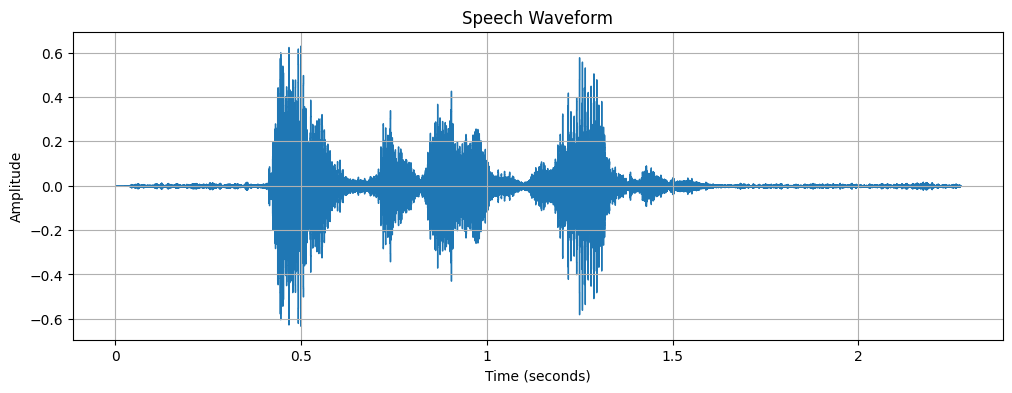

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import librosa.display

audio = np.asarray(audio, dtype=np.float32)

if audio.ndim == 2:
    audio = audio.mean(axis=1)

plt.figure(figsize=(12, 4))

librosa.display.waveshow(audio, sr=sr)

plt.title("Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

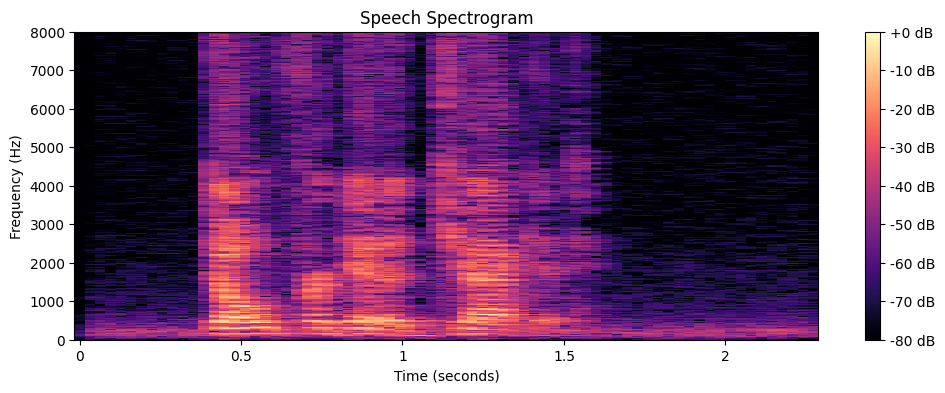

In [27]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

audio = np.asarray(audio, dtype=np.float32)

if audio.ndim == 2:
    audio = audio.mean(axis=1)

D = librosa.stft(audio)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(
    S_db, sr=sr, x_axis="time",
    y_axis="hz", cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Speech Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.show()

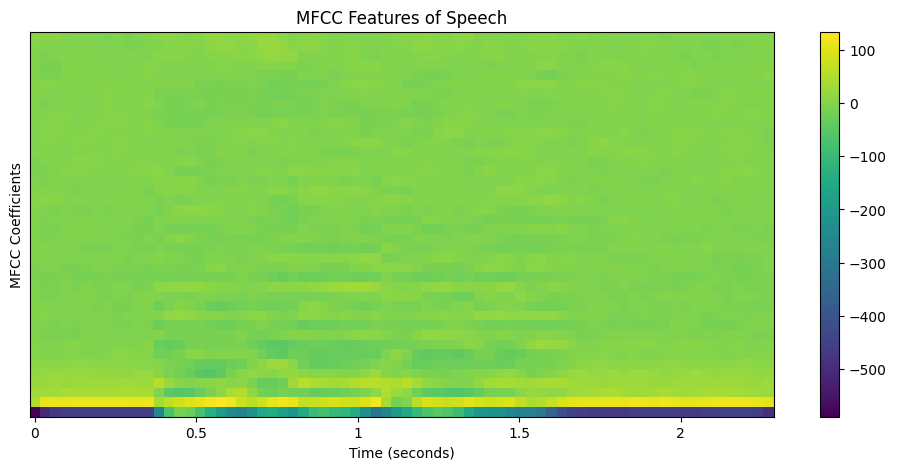

In [28]:
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=40
)

plt.figure(figsize=(12, 5))
librosa.display.specshow(
    mfcc, sr=sr,
    x_axis="time",
    cmap="viridis"
)
plt.colorbar()
plt.title("MFCC Features of Speech")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficients")
plt.show()

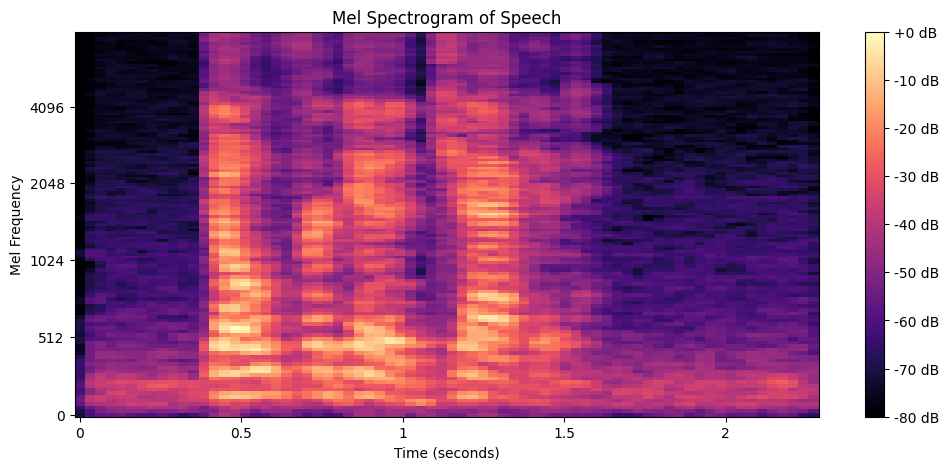

In [29]:
mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=128
)

mel_db = librosa.power_to_db(mel, ref=np.max)

plt.figure(figsize=(12, 5))
librosa.display.specshow(
    mel_db,
    sr=sr,
    x_axis="time",
    y_axis="mel",
    cmap="magma"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram of Speech")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency")
plt.show()